# **Práctica Final - IA con inspiración biológica**

Máster en Ciencia y Tecnología de la Carlos III de Madrid 

Andrea López Salazar

## **1. Introducción y objetivo**

El problema que se plantea en la práctica es una regresión supervisada con atributos `X` y salida continua `y`. Se busca un modelo `M` tal que $\hat{y}=M(x) \approx y$. El objetivo es, por ende, un programa `P` que reciba $(X_t, y_t)$ que aprenda una transformación de atributos tal que $X_t ' = P(X_t)$ y, con la transformación aprendida: $X_v '= v(X_v)$.

El criterio de éxito es que con el mismo modelo, el MAE de validación don los atributos originales sea mayor que el MAE con los transformados. Esto bajo la restricción de que la validación jamás se usa para aprender.

## **2. Configuración y datos**

### 2.1. Configuración

In [ ]:
# Configuracion 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

seed            = 13
particiones     = 13
semillas        = [seed + i for i in range(particiones)]
tam_test        = 0.3

rutas_datasets  = {
    "diabetes"   : ("DATASETS/Diabetes.csv", "target"),
    "california" : ("DATASETS/California.csv", "MedHouseVal"),
}



diabetes (442, 11)
california (20640, 9)


### 2.2. Carga

In [3]:
# Carga
datos = {}

for nombre, (ruta, objetivo) in rutas_datasets.items(): 
    df              = pd.read_csv(ruta)
    datos[nombre]   = (df.drop(columns=objetivo), df[objetivo].values)
    print(nombre, df.shape)

diabetes (442, 11)
california (20640, 9)


### 2.3. Partición 

In [5]:
from sklearn.model_selection import train_test_split

def split(nombre, semilla): 
    X, y    = datos[nombre]
    return train_test_split(X, y, test_size=tam_test, random_state=seed)

- Usamos 13 particiones con semillas consecutivas porque una sola partición no sería fiable. Usamos primero la semilla 13 para que sea reproducible. Además esto nos permite sacar medidas estadísticas como la media y desviación para realizar test estadísticos.

- Se usa una partición de test/entrenamiento de 30/70. 

- Hacemos nosotros la partición del enunciado entre el entrenamiento y la validación. 

### 2.4. Comprobamos la calidad

In [6]:
for nombre, (X,y) in datos.items(): 
    Xt, Xv, yt, yv  = split(nombre, seed)
    print(nombre)
    print("     nulos: ", X.isna().sum().sum() + np.isnan(y).sum())
    print("     duplicados:", pd.concat([X, pd.Series(y, index=X.index, name="y")], axis=1).duplicated().sum())
    print("     tipos: ", set(X.dtypes.astype(str)))
    print("     entrenamiento / validación: ", Xt.shape[0], "/", Xv.shape[0])

diabetes
     nulos:  0
     duplicados: 0
     tipos:  {'float64'}
     entrenamiento / validación:  309 / 133
california
     nulos:  0
     duplicados: 0
     tipos:  {'float64'}
     entrenamiento / validación:  14448 / 6192


Comprobamos que en ambos datasets no hay valores nulos, ni tampoco duplicados. Además, todos los tipos son numéricos. No necesitamos hacer una limpieza. Cabe resaltar que como la validación de Diabetes solo tiene 133 muestras, el error será más ruidoso que en el caso de California.

## **3. Descripción de los datos**

### 3.1. Estadísticos descriptivos

In [7]:
for nombre, (X,y) in datos.items(): 
    print(nombre)
    print(pd.concat([X, pd.Series(y, index=X.index, name="y")], axis=1).describe().T.round(3))
    print()

diabetes
     count     mean     std     min     25%      50%      75%      max
age  442.0   -0.000   0.048  -0.107  -0.037    0.005    0.038    0.111
sex  442.0    0.000   0.048  -0.045  -0.045   -0.045    0.051    0.051
bmi  442.0   -0.000   0.048  -0.090  -0.034   -0.007    0.031    0.171
bp   442.0   -0.000   0.048  -0.112  -0.037   -0.006    0.036    0.132
s1   442.0   -0.000   0.048  -0.127  -0.034   -0.004    0.028    0.154
s2   442.0    0.000   0.048  -0.116  -0.030   -0.004    0.030    0.199
s3   442.0   -0.000   0.048  -0.102  -0.035   -0.007    0.029    0.181
s4   442.0   -0.000   0.048  -0.076  -0.039   -0.003    0.034    0.185
s5   442.0    0.000   0.048  -0.126  -0.033   -0.002    0.032    0.134
s6   442.0    0.000   0.048  -0.138  -0.033   -0.001    0.028    0.136
y    442.0  152.133  77.093  25.000  87.000  140.500  211.500  346.000

california
              count      mean       std      min      25%       50%       75%  \
MedInc      20640.0     3.871     1.900    0.5

- La media en el dataset de Diabetes es 0, lo que nos da una pista de que este dataset está ya estandarizado, todos los valores están en la misma escala. 
- Esto no ocurre con el dataset de California, donde los valores tienen distintas medias y varían entre valores muy distintos. Además, encontramos varios máximos que difieren mucho en distancia del percentil 75.

### 3.2. Variable objetivo y topes

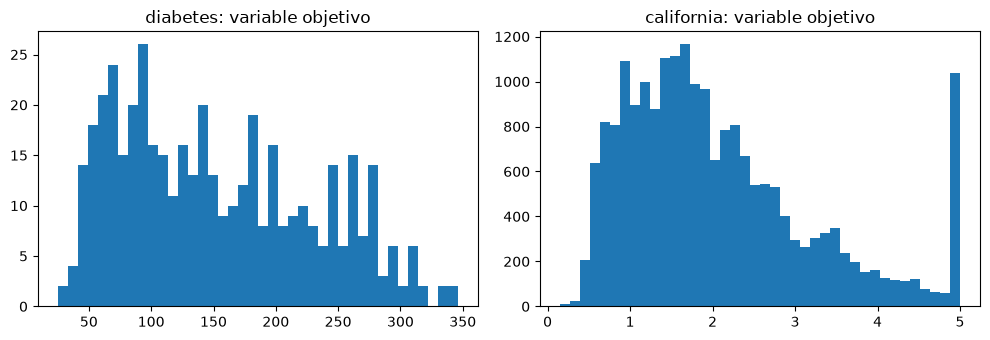

In [8]:
fig, ejes = plt.subplots(1,2,figsize=(10,3.5))
for eje, (nombre, (X,y)) in zip(ejes, datos.items()): 
    eje.hist(y, bins = 40)
    eje.set_title(nombre + ": variable objetivo")

plt.tight_layout()
plt.show()

En diabetes la variable objetivo se distribuye de manera normal con una cola hacia la derecha. En el caso de California, también tenemos una cola hacia la derecha, pero observamos un pico en el valor máximo. 

In [9]:
Xc, yc = datos["california"]
print("California, casas con el valor máximo de MedHouseVal: ", (yc==yc.max()).sum(), "de", len(yc), "| máximo:", yc.max())
print("California, casas con HouseAge == 52:", (Xc["HouseAge"] == 52).sum())

California, casas con el valor máximo de MedHouseVal:  965 de 20640 | máximo: 5.00001
California, casas con HouseAge == 52: 1273


El resultado anterior nos da a entender que el valor de 52 actúa como tope o pico, donde cualquier casa con 52 años o más acaba obteniendo este valor. 

### 3.3. Distribución de los atributos 

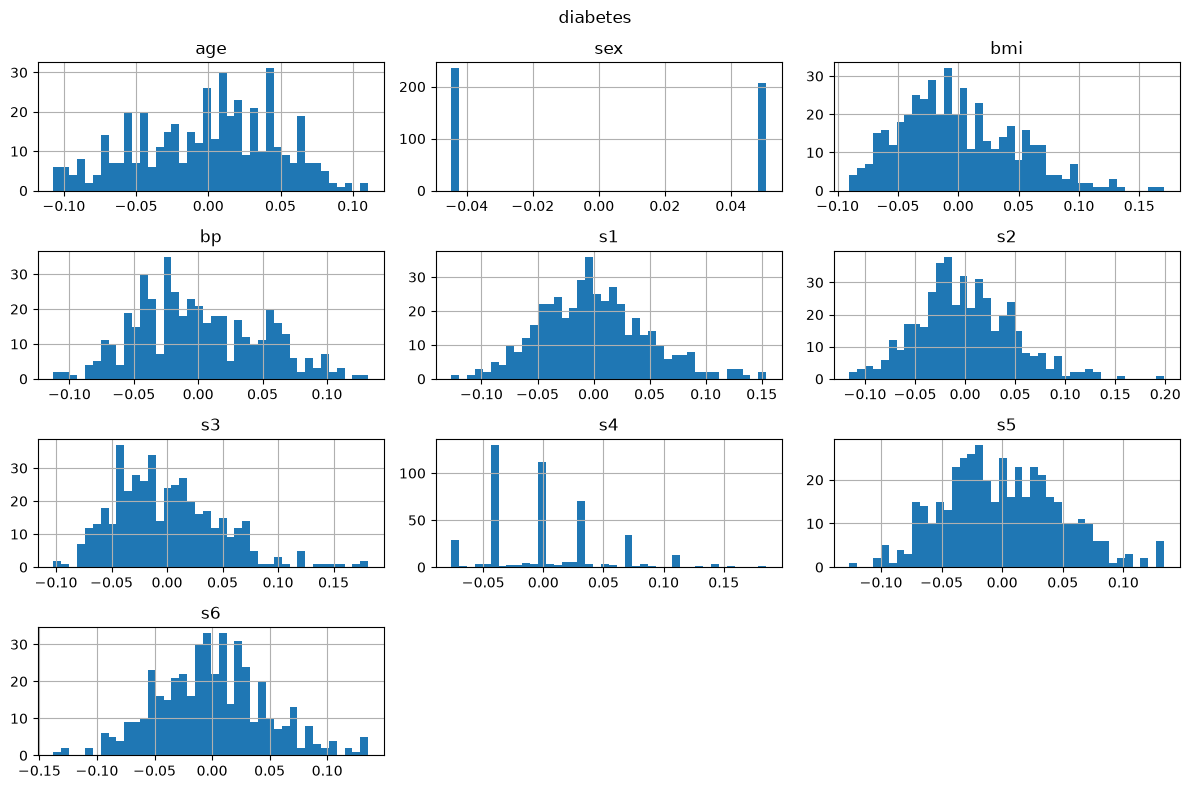

diabetes  - asimetría de los atributos: 
s3     0.80
s4     0.74
bmi    0.60
s2     0.44
s1     0.38
bp     0.29
s5     0.29
s6     0.21
sex    0.13
age   -0.23



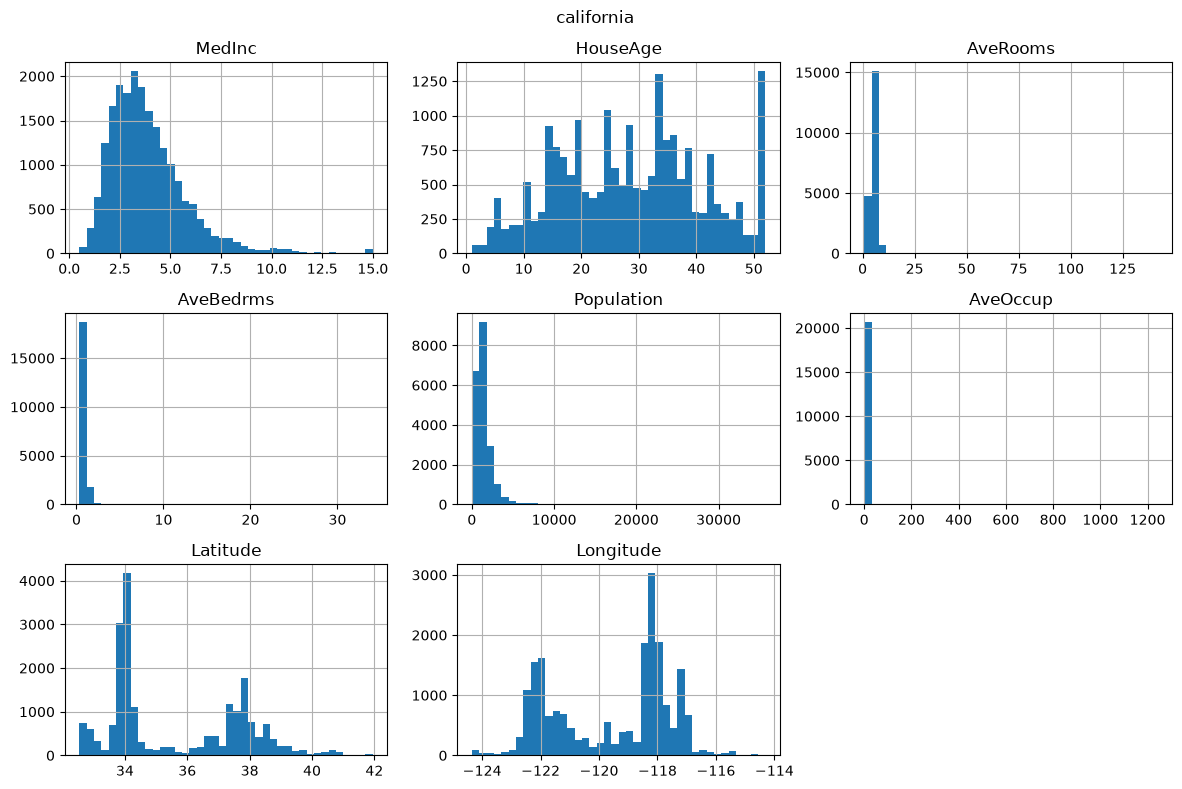

california  - asimetría de los atributos: 
AveOccup      97.64
AveBedrms     31.32
AveRooms      20.70
Population     4.94
MedInc         1.65
Latitude       0.47
HouseAge       0.06
Longitude     -0.30



In [12]:
for nombre, (X,y) in datos.items(): 
    X.hist(bins=40, figsize=(12,8))
    plt.suptitle(nombre)
    plt.tight_layout()
    plt.show()

    print(nombre, " - asimetría de los atributos: ")
    print(X.skew().round(2).sort_values(ascending=False).to_string())
    print()

#### Variables de Diabetes
- `sex` es una variable binaria con dos valores únicos. Es una categórica que ha sido binarizada para poder ser utilizada por el modelo de regresión. Pero no es una variable continua. 

- `s4` también tiene picos de valores, como si varias de las entradas compartieran el mismo valor para esta variable.

- El resto de variables parece seguir una distribución normal, `bp` a simple vista podría llegar a verse como una bimodal. 

- Podemos ver los valores de asimetría de los atributos listados.

#### Variables de California

- Por la escala usada en las gráficas, podemos ver que varias de las variables de esta dataset se representan por picos muy pronunciados. 

- Las dos variables de coordenadas son bimodales,  como podemos ver por los dos picos principales en la distribución de sus valores. 

- `MedInc` presenta una cola pesada hacia la derecha. 


### 3.4. Correlaciones entre las variables

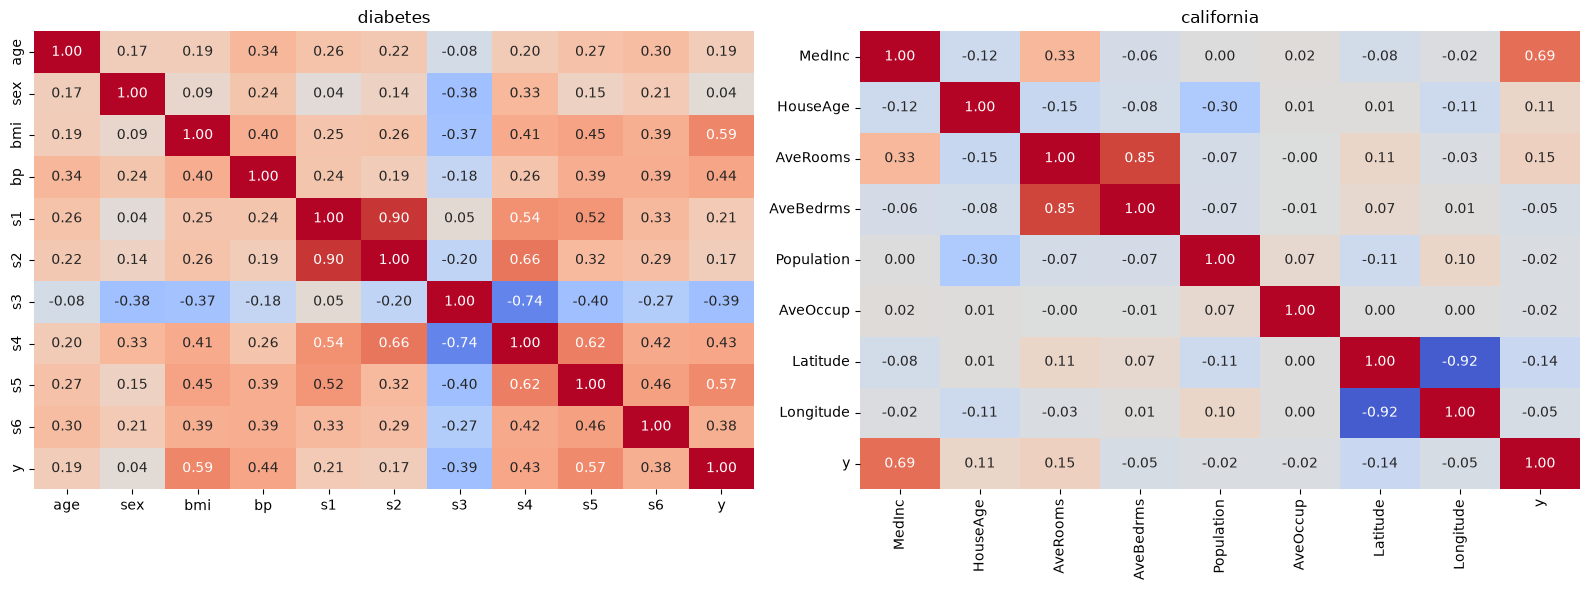

In [14]:
import seaborn as sns 

fig, ejes = plt.subplots(1, 2, figsize=(16, 6))

for eje, (nombre, (X,y)) in zip(ejes, datos.items()): 
    c = pd.concat([X, pd.Series(y, index=X.index, name="y")], axis=1).corr()
    sns.heatmap(c, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=eje, cbar=False)
    eje.set_title(nombre)

plt.tight_layout()
plt.show()

- En el dataset de Diabetes vemos correlaciones bajas entre las variables por lo general, las variables con correlación absoluta más alta son: s2 con s1 con 0.90; s4 con s3 con -0.745; y s4 con s2 con un 0.66. 

- En el dataset de California tenemos una situación parecida. Las variables con mayor correlación entre ellas son AveBedrms jutno a AveRooms con un 0.85 (lo cual puede significar que la presencia de ambas es redundante); las coordenadas, con una correlación entre sí de -0.92; y finalmente también vemos que la variable objetivo tiene una correlación de 0.69 con MedInc.

### 3.5. Conclusiones

- California presenta escalas muy distintas, por lo que en caso de usar distancias, quedarían dominadas por las variables más grandes. La transformación debería estadarizar y aprender un peso por atributo. 

- California también presenta colas muy largas, por lo que aplicar un exponente de Yeo-Johnson por atributo podría ayudar con este tipo de situaciones.

- Hay correlaciones débiles con la variable objetivo salvo por el caso de California con MedInc, pero esto no significa que deban descartarse el resto. 

- Existen variables de tope, que ponen un techo y no tienen continuidad. No se corrigen, pero ponen un límite al MAE alcanzable. 

- Hay redundancia entre atributos, por lo que los pesos ayudan además a reducir la influencia de las variables redundantes presentes. 

- El dataset de Diabetes está ya estandarizado, con una variable binaria. Este tipo de datos tiene riesgo de sobreajuste, por lo que se evaluará en 10 particiones.

- y tiene distintas escalas. Por ende, el MAE no es comparable entre los dos datasets.

## **4. Líneas base**

## **5. Método: transformación y CMA-ES**

## **6. Experimento principal**

## **7. Controles del método**

## **8. Resultados**

## **9. Análisis**